In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# MultiSCALE files
from multiscale import RCCA, model

## Synthetic data

/home/anw/scdam/tmp/ipykernel_575041/2177605592.py:32: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  data = rng.multivariate_normal(np.zeros(2*p), Sigma, size=n)


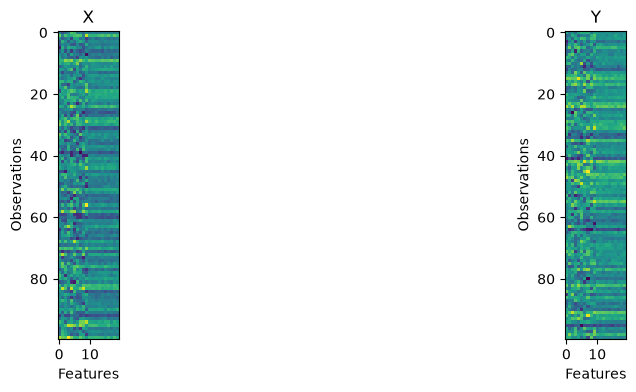

In [2]:
def make_random_data(p=50, k=10, rho=0.5, r_high=0.7, r_low=0.05, n=5000, seed=0):
    """
    Generate random data with blocks of (un)correlated data.

    Parameters
    ----------
    p : int, optional
        Number of variables. The default is 50.
    k : int, optional
        Number of variables which should have high correlations. The default is 10.
    r_high : float, optional
        High correlation. The default is 0.7.
    r_low : float, optional
        Low. The default is 0.05.
    n : int, optional
        Number of observations. The default is 5000.
    seed : int, optional
        seed. The default is 0.

    Returns
    -------
    X : np.array
    Y : np.array
    """
    rng = np.random.default_rng(seed)
    Sxx = np.full((p, p), 0.5)
    Syy = np.full((p, p), 0.5)
    Sxy = np.zeros((p, p))
    Sxy[np.diag_indices(k)] = r_high        
    np.fill_diagonal(Sxy[k:, k:], r_low)    
    Sigma = np.block([[Sxx, Sxy], [Sxy.T, Syy]])
    data = rng.multivariate_normal(np.zeros(2*p), Sigma, size=n)
    
    return data[:, :p], data[:, p:]

N, P = 100, 20
X, Y = make_random_data(p=P, k=10, rho=0.5, r_high=0.8, r_low=0.05, n=N)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].imshow(X)
axs[1].imshow(Y)
axs[0].set_xlabel("Features")
axs[0].set_ylabel("Observations")
axs[0].set_title("X")
axs[1].set_xlabel("Features")
axs[1].set_ylabel("Observations")
axs[1].set_title("Y")
plt.show()

## Networks creation

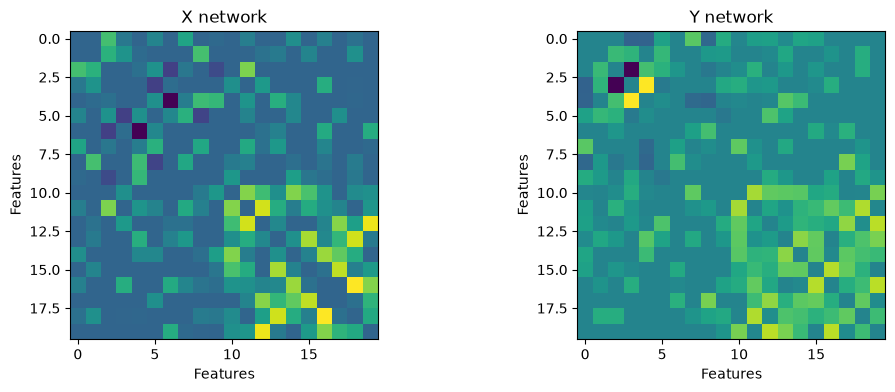

In [3]:
# Using ebic glasso
X_net = model.ebic_glasso(pd.DataFrame(X), gamma=.5, n_lambdas=10, max_iter=10000)["network"]
Y_net = model.ebic_glasso(pd.DataFrame(Y), gamma=.5, n_lambdas=10, max_iter=10000)["network"]

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].imshow(X_net)
axs[1].imshow(Y_net)
axs[0].set_xlabel("Features")
axs[0].set_ylabel("Features")
axs[0].set_title("X network")
axs[1].set_xlabel("Features")
axs[1].set_ylabel("Features")
axs[1].set_title("Y network")
plt.show()

## Inter-layer links and supra-adjacency matrix

ADMM terminated after 295 iterations with status: optimal.


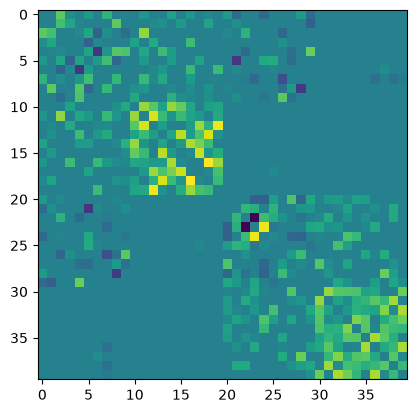

In [4]:
# RCCA
X_loadings, Y_loadings = model.RCCA_multi(
                    X=X, 
                    Y=Y,
                    lambda1=10,
                    lambda2=10
                )
# RSA
inter_layers = model.partial_interlayer(
                    X_loadings=X_loadings, 
                    Y_loadings=Y_loadings, 
                    N=N,
                    lambda1=0.1
                )

# Supra-adjacency matrix
supra = model.build_supra_adjacency(intra_layers=[X_net, Y_net], inter_layers=[inter_layers], layer_size=[P, P])

plt.imshow(supra)

## Bridge strength

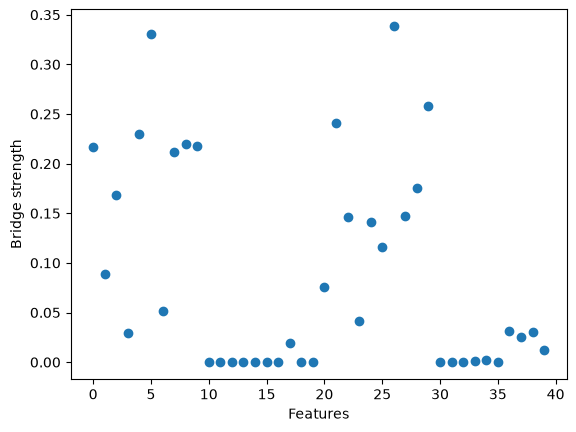

In [5]:
import sys, os
sys.path.insert(0, os.path.abspath("MuxVizPy/src"))
from MuxVizPy import versatility

bridge_strength = versatility.get_bridge_strength(supra, n=2, l=[P, P])

plt.scatter(np.arange(2*P), bridge_strength)
plt.xlabel("Features")
plt.ylabel("Bridge strength")
plt.show()